In [13]:
import os
import zipfile
from pathlib import Path


# Extract the ZIP file
zip_file_path = "/archive.zip"  # Path to the zip file
extract_path = "ArchiveZip"  # Folder to extract contents

# Extracting the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)


# Create train, test and validation directories for both dog and cat images
os.makedirs("train")
os.makedirs("test")
os.makedirs("validation")
os.makedirs("train/cats")
os.makedirs("train/dogs")
os.makedirs("test/cats")
os.makedirs("test/dogs")
os.makedirs("validation/cats")
os.makedirs("validation/dogs")

In [16]:
import shutil
from PIL import Image
import random

def is_valid_image(image_path):
    try:
        with Image.open(image_path) as img:
            img.verify()  # Verify the image
        return True
    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return False

# Create arrays of image path of cats and dogs
dog_images = []
cat_images = []

# Move valid dog images
for image_name in os.listdir("/ArchiveZip/PetImages/Cat"):
    image_path = os.path.join("/ArchiveZip/PetImages/Cat", image_name)
    if is_valid_image(image_path):
        cat_images.append(image_path)

# Move valid cat images
for image_name in os.listdir("/ArchiveZip/PetImages/Dog"):
    image_path = os.path.join("/ArchiveZip/PetImages/Dog", image_name)
    if is_valid_image(image_path):
        dog_images.append(image_path)

# Split into training test and validation sets
total_count = len(dog_images)
test_count = int(total_count * 0.05)  # 5% for testing
validation_count = int(total_count * 0.10)  # 10% for validation

dog_test_images = dog_images[:test_count]  # First 5% for testing
dog_validation_images = dog_images[test_count:test_count + validation_count]  # Next 10% for validation
dog_train_images = dog_images[test_count + validation_count:]  # Remaining 85% for training


total_count = len(cat_images)
test_count = int(total_count * 0.05)  # 5% for testing
validation_count = int(total_count * 0.10)  # 10% for validation

cat_test_images = cat_images[:test_count]
cat_validation_images = cat_images[test_count:test_count + validation_count]
cat_train_images = cat_images[test_count + validation_count:]

# Move train images
for img_path in dog_train_images:
    shutil.move(img_path, "/content/train/dogs")
for img_path in cat_train_images:
    shutil.move(img_path, "/content/train/cats")
# Move validation images
for img_path in dog_validation_images:
    shutil.move(img_path, "/content/validation/dogs")
for img_path in cat_validation_images:
    shutil.move(img_path, "/content/validation/cats")
# Move test images
for img_path in dog_test_images:
    shutil.move(img_path, "/content/test/dogs")
for img_path in cat_test_images:
    shutil.move(img_path, "/content/test/cats")


print("Images have been processed and split into Train and Test directories.")


Error processing /ArchiveZip/PetImages/Cat/666.jpg: cannot identify image file '/ArchiveZip/PetImages/Cat/666.jpg'
Error processing /ArchiveZip/PetImages/Cat/Thumbs.db: cannot identify image file '/ArchiveZip/PetImages/Cat/Thumbs.db'
Error processing /ArchiveZip/PetImages/Dog/11702.jpg: cannot identify image file '/ArchiveZip/PetImages/Dog/11702.jpg'
Error processing /ArchiveZip/PetImages/Dog/Thumbs.db: cannot identify image file '/ArchiveZip/PetImages/Dog/Thumbs.db'
Images have been processed and split into Train and Test directories.


In [17]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
# Set image size for the model input
IMG_SIZE = (200, 200)  # Resize images

train_dir = 'train'  # Path to the Train directory
test_dir = 'test'  # Path to the Test directory
validation_dir = 'validation'  # Path to the Validation directory

# Training Data Generator with Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,            # Normalize pixel values to [0, 1]
    shear_range=0.1,           # Random shear transformations
    zoom_range=0.2,            # Random zoom
    horizontal_flip=True,      # Randomly flip images horizontally
    width_shift_range=0.1,     # Randomly shift images horizontally
    height_shift_range=0.1     # Randomly shift images vertically
)

# Validation Data Generator
validation_datagen = ImageDataGenerator(
    rescale=1./255             # Only normalize pixel values
)

# Testing Data Generator
test_datagen = ImageDataGenerator(
    rescale=1./255             # Only normalize pixel values
)


# Create train and test generators for the images
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=True
)

validation_generator = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Build the CNN model
model = models.Sequential()

# Convolutional Layer 1
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(200, 200, 3)))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.15))

# Convolutional Layer 2
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.15))

# Convolutional Layer 3
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.15))

# Flatten the output from the convolutional layers
model.add(layers.Flatten())

# Fully Connected Layer 1
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

# Output layer with a sigmoid activation for binary classification
model.add(layers.Dense(1, activation='sigmoid'))

print("Compiling model")
# Compile the model
model.compile(
    optimizer = 'adam',
    loss='binary_crossentropy',  # Binary crossentropy for binary classification
    metrics=['accuracy']  # Track accuracy during training
)
print("Compiling done")


Found 21252 images belonging to 2 classes.
Found 2498 images belonging to 2 classes.
Found 1248 images belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Compiling model
Compiling done


In [18]:
#Train the model

history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator,
    callbacks=[early_stopping]
)




Epoch 1/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.6087 - loss: 0.8204

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


665/665 ━━━━━━━━━━━━━━━━━━━━ 324s 461ms/step - accuracy: 0.6378 - loss: 0.6995 - val_accuracy: 0.6465 - val_loss: 0.6126
Epoch 2/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 265s 398ms/step - accuracy: 0.7252 - loss: 0.5358 - val_accuracy: 0.7726 - val_loss: 0.4787
Epoch 3/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 259s 390ms/step - accuracy: 0.7616 - loss: 0.4882 - val_accuracy: 0.7550 - val_loss: 0.4848
Epoch 4/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 267s 402ms/step - accuracy: 0.7876 - loss: 0.4490 - val_accuracy: 0.8231 - val_loss: 0.3982
Epoch 5/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 261s 392ms/step - accuracy: 0.8123 - loss: 0.4119 - val_accuracy: 0.8251 - val_loss: 0.4091
Epoch 6/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 258s 388ms/step - accuracy: 0.8314 - loss: 0.3750 - val_accuracy: 0.8046 - val_loss: 0.4271
Epoch 7/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 258s 387ms/step - accuracy: 0.8489 - loss: 0.3479 - val_accuracy: 0.8283 - val_loss: 0.3792
Epoch 8/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 263s 395ms/step - accuracy: 0.8461 - loss: 0.34

In [19]:
# Save the model
model.save('model.h5')
print("Saved model")

Saved model


In [28]:
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
result = model.predict(test_generator,batch_size = 32,verbose = 0)

y_pred = np.where(result > 0.5, 1, 0)

y_true = test_generator.labels

# Evaluate
loss,acc = model.evaluate(test_generator, batch_size = 32, verbose = 0)

print('The accuracy of the model for testing data is:',acc*100)
print('The Loss of the model for testing data is:',loss)
labels =['Cat','Dog']
print(classification_report(y_true, y_pred,target_names=labels))

The accuracy of the model for testing data is: 88.30128312110901
The Loss of the model for testing data is: 0.31229525804519653
              precision    recall  f1-score   support

         Cat       0.88      0.89      0.88       624
         Dog       0.89      0.88      0.88       624

    accuracy                           0.88      1248
   macro avg       0.88      0.88      0.88      1248
weighted avg       0.88      0.88      0.88      1248



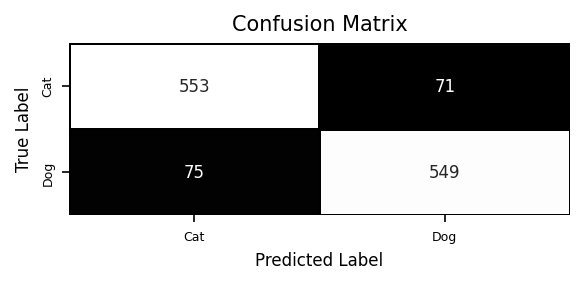

In [29]:
confusion_mtx = confusion_matrix(y_true, y_pred)

# Create the confusion matrix
f, ax = plt.subplots(figsize=(4, 2), dpi=150)
sns.heatmap(confusion_mtx, annot=True, fmt='.0f', cmap="gist_yarg_r",
            linewidths=0.5, linecolor="black",
            xticklabels=labels, yticklabels=labels,
            annot_kws={"size": 8},  # Smaller annotation font
            ax=ax, cbar=False)

plt.xlabel("Predicted Label", fontsize=8)
plt.ylabel("True Label", fontsize=8)
plt.title("Confusion Matrix", fontsize=10)

plt.xticks(fontsize=6)
plt.yticks(fontsize=6)

plt.tight_layout()
plt.show()


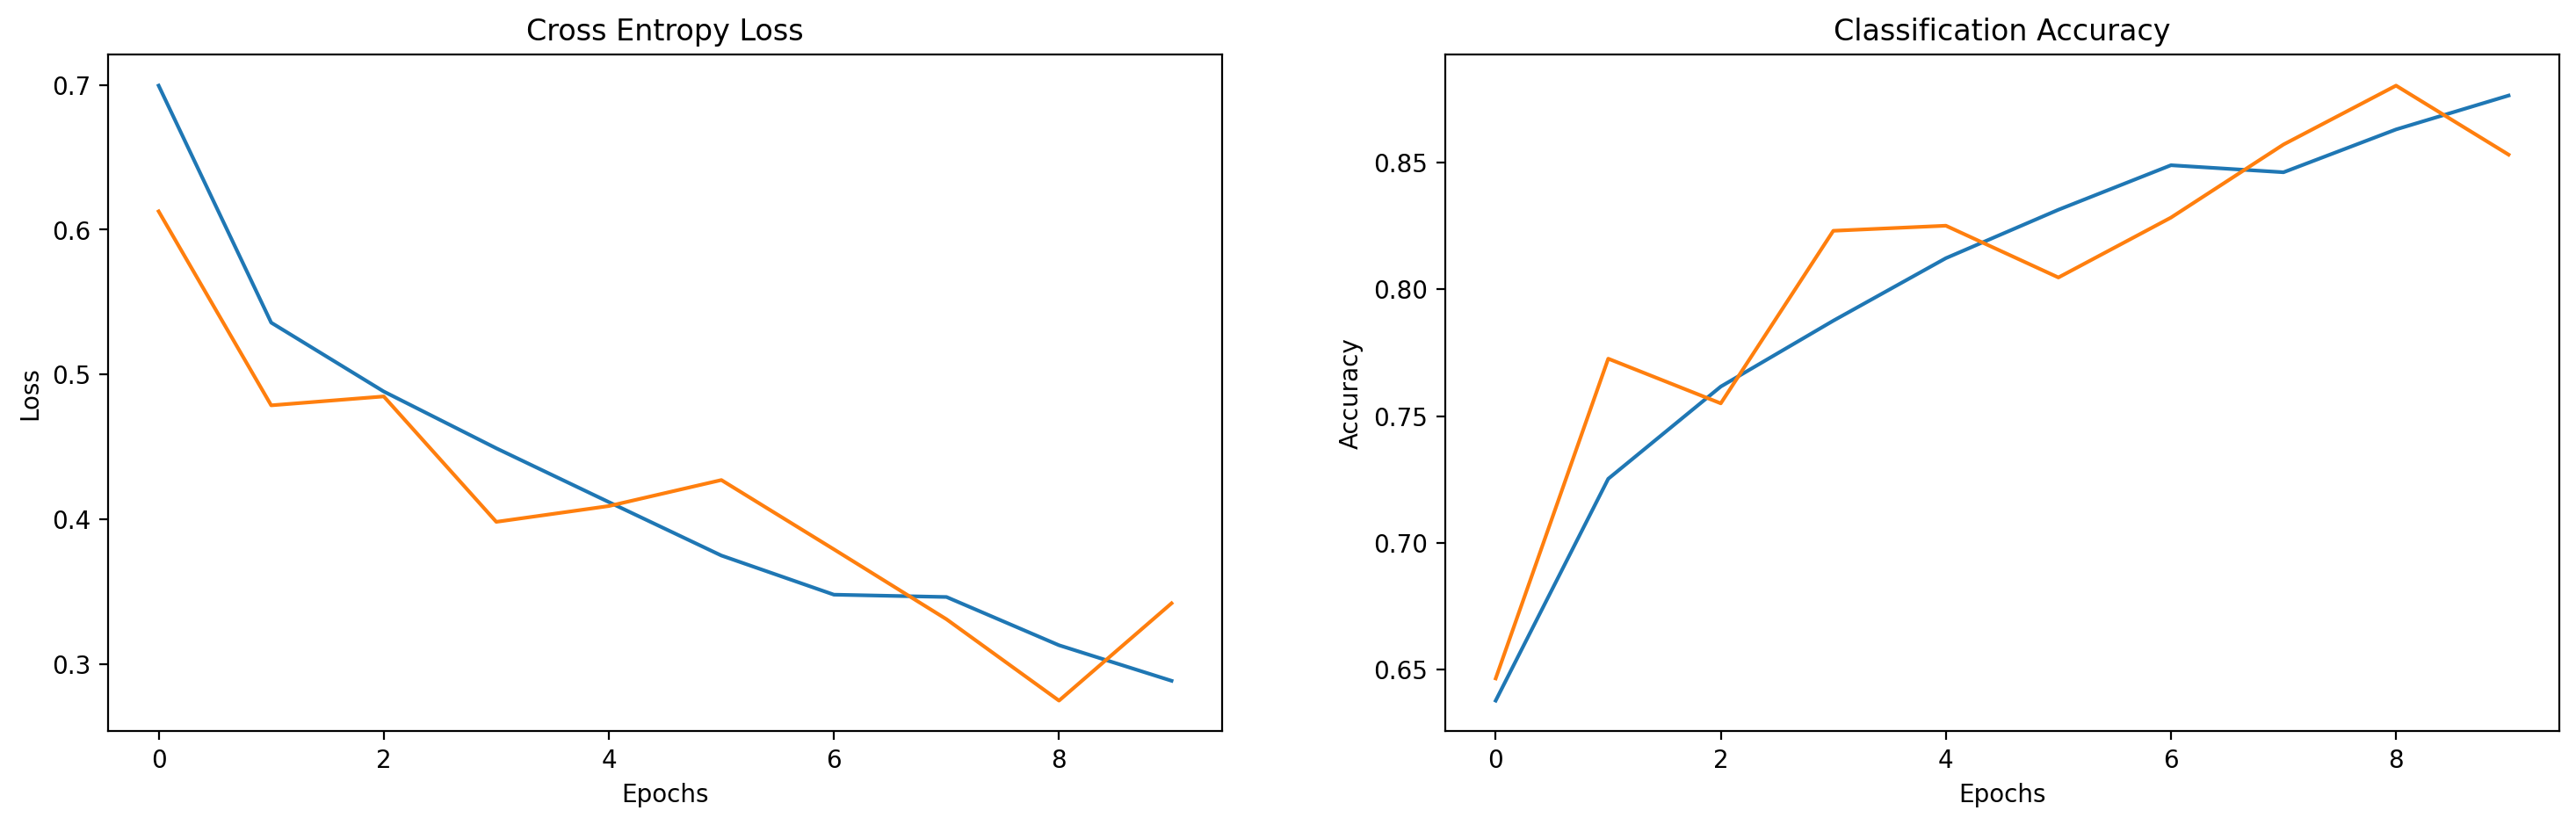

In [30]:

import pandas as pd
import matplotlib.pyplot as plt

error = pd.DataFrame(history.history)

# Plot accuracy and loss

plt.figure(figsize=(18,5),dpi=200)
plt.subplot(121)
plt.title('Cross Entropy Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.plot(error['loss'])
plt.plot(error['val_loss'])

plt.subplot(122)
plt.title('Classification Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.plot(error['accuracy'])
plt.plot(error['val_accuracy'])

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


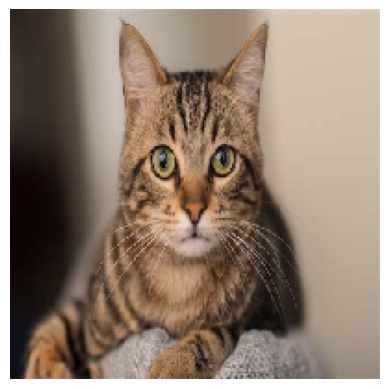

[0.00015351]
Predicted: Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


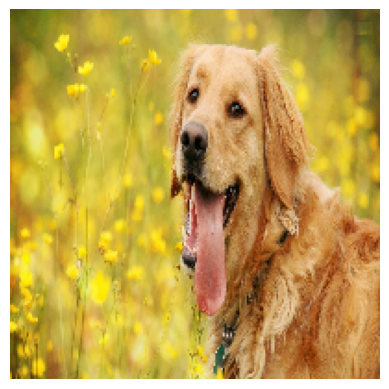

[0.9979367]
Predicted: Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


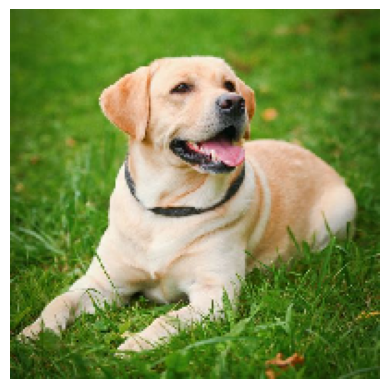

[0.9999409]
Predicted: Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


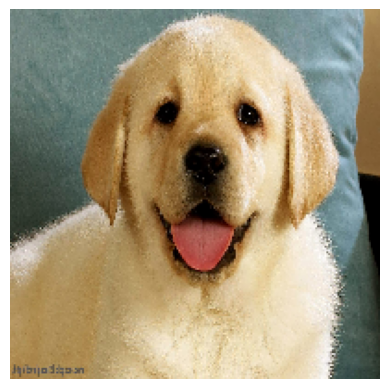

[0.99840754]
Predicted: Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


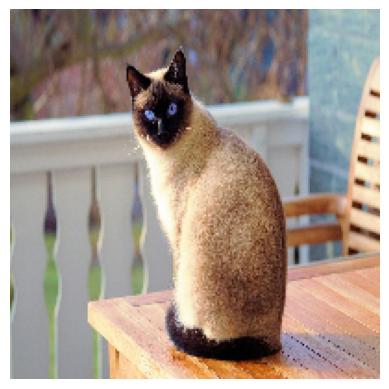

[0.5729581]
Predicted: Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


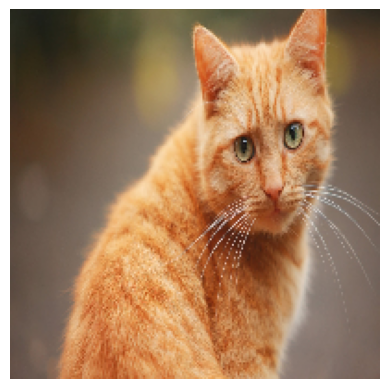

[0.18723717]
Predicted: Cat


In [32]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

def predict_img(image_path):
    # Load and preprocess the image
    img = image.load_img(image_path, target_size=(200, 200))  # Resize image to the same size as the input of the model
    img_array = image.img_to_array(img)  # Convert image to an array
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    img_array = img_array / 255.0  # Normalize the image

    # Make a prediction
    prediction = model.predict(img_array)  # Predict class for the image

    # Display the image and the prediction
    plt.imshow(img)
    plt.axis('off')  # Turn off axis for better display
    plt.show()
    print(prediction[0])
    # Interpret the prediction
    if prediction[0] < 0.5:
        print("Predicted: Cat")
    else:
        print("Predicted: Dog")

# Sample predictions from the internet to showcase the model
predict_img('CatTestImage.png')
predict_img('DogTestImage.jpg')
predict_img('dog2.png')
predict_img('dog3.jpg')
predict_img('cat2.jpeg')
predict_img('cat3.jpg')




In [33]:
# Import the necessary modules
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from PIL import Image
import os

# Define the image dimensions
IMG_HEIGHT, IMG_WIDTH = 75, 75

# Function to load and preprocess images
def load_images(image_paths):

    data = []
    labels = []
    print("Loading image",image_paths[0])
    for image_path in image_paths:
        try:
            img = Image.open(image_path).resize((IMG_HEIGHT, IMG_WIDTH))  # Resize image
            img_array = np.array(img) / 255.0  # Normalize pixel values to [0, 1]
            img.close()

            if img_array.shape == (IMG_HEIGHT, IMG_WIDTH, 3):  # Ensure the image is RGB
                data.append(img_array)  # Don't flatten the image yet
                # Assign label based on folder name
                label = 1 if "dogs" in image_path else 0
                labels.append(label)
        except Exception as e:
            print(f"Error processing image {image_path}: {e}")
    return np.array(data), np.array(labels)

# Define directories
train_dir = "train"
validation_dir = "validation"
test_dir = "test"

# Load training data
train_dog_images = [os.path.join("train/dogs", img) for img in os.listdir("train/dogs")]
train_cat_images = [os.path.join("train/cats", img) for img in os.listdir("train/cats")]
train_data, train_labels = load_images(train_dog_images + train_cat_images)

# Load validation data
val_dog_images = [os.path.join("validation/dogs", img) for img in os.listdir("validation/dogs")]
val_cat_images = [os.path.join("validation/cats", img) for img in os.listdir("validation/cats")]
val_data, val_labels = load_images(val_dog_images + val_cat_images)

# Load test data
test_dog_images = [os.path.join("test/dogs", img) for img in os.listdir("test/dogs")]
test_cat_images = [os.path.join("test/cats", img) for img in os.listdir("test/cats")]
test_data, test_labels = load_images(test_dog_images + test_cat_images)



Loading image train/dogs/2495.jpg
Loading image validation/dogs/1082.jpg


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Loading image test/dogs/4173.jpg


In [35]:

# Flatten the images for KNN
train_data = train_data.reshape(len(train_data), -1)
from sklearn.model_selection import GridSearchCV

# Train the KNN model
print("Training Model")
# Define the KNN model
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1)
knn.fit(train_data, train_labels)
print("Model training done")

# Validate the model
val_data_flat = val_data.reshape(len(val_data), -1)  # Flatten validation data
val_preds = knn.predict(val_data_flat)

# Calculate predictions for validation data
val_accuracy = accuracy_score(val_labels, val_preds)
print(f"Validation Accuracy: {val_accuracy:.2f}")

# Display classification report for validation data
print("*** Classification Report (Validation) ***")
print(classification_report(val_labels, val_preds, target_names=["Cat", "Dog"]))

# Test the model
test_data_flat = test_data.reshape(len(test_data), -1)  # Flatten test data
test_preds = knn.predict(test_data_flat)
test_accuracy = accuracy_score(test_labels, test_preds)
print(f"Test Accuracy: {test_accuracy:.2f}")

# Display classification report for test data
print("*** Classification Report (Test) ***")
print(classification_report(test_labels, test_preds, target_names=["Cat", "Dog"]))


Training Model
Model training done
Validation Accuracy: 0.61
*** Classification Report (Validation) ***
              precision    recall  f1-score   support

         Cat       0.59      0.69      0.64      1245
         Dog       0.63      0.53      0.57      1241

    accuracy                           0.61      2486
   macro avg       0.61      0.61      0.61      2486
weighted avg       0.61      0.61      0.61      2486

Test Accuracy: 0.57
*** Classification Report (Test) ***
              precision    recall  f1-score   support

         Cat       0.56      0.69      0.62       622
         Dog       0.60      0.46      0.52       623

    accuracy                           0.57      1245
   macro avg       0.58      0.57      0.57      1245
weighted avg       0.58      0.57      0.57      1245

